# Bedah Kasus 3: Dataset Pengamatan Cuaca
### Pembuatan Data Sintetis, Analisis Deskriptif, dan Visualisasi Berdasarkan Skala Pengukuran

| | |
|---|---|
| **Nama** | **Ganesia Alkhan** |
| **NIM** | **241051019** |

---
**Daftar isi**
1. Pemahaman kasus & skala pengukuran
2. Persiapan lingkungan
3. Pembuatan data sintetis (1.000 baris)
4. Validasi struktur & kualitas data
5. Analisis **Kota** (nominal)
6. Analisis **Kondisi** (nominal) & hubungannya dengan Kota
7. Analisis **Suhu** (numerik interval)
8. Analisis **Kelembaban** (numerik rasio)
9. Hubungan antar variabel
10. Temuan utama & kesimpulan
11. Menjalankan dashboard Streamlit

## 1. Pemahaman Kasus & Skala Pengukuran

Gambar tugas menunjukkan dataset pengamatan cuaca dengan **4 kolom** dan 2 baris contoh. Kasus ini menekankan perbedaan skala **interval** dan **rasio**, dua skala numerik yang sering tertukar:

| Kolom | Contoh | Skala | Penjelasan | Visualisasi yang sesuai |
|---|---|---|---|---|
| **Kota** | Jakarta, Bandung | Kategorik - **Nominal** | Label teks tanpa urutan | Bar chart / Pie chart |
| **Suhu (°C)** | 32,5; 24,0 | Numerik - **Interval** | Jarak antar suhu sama, tetapi 0 °C **bukan** berarti "tidak ada suhu". Aturan rasio tidak berlaku (20 °C bukan 2x lebih panas dari 10 °C) | Histogram, box plot |
| **Kelembaban (%)** | 75; 85 | Numerik - **Rasio** | 0% berarti benar-benar tidak ada kelembaban (nol absolut), sehingga rasio bermakna (80% = 2x 40%) | Histogram, box plot |
| **Kondisi** | Cerah, Hujan | Kategorik - **Nominal** | Label teks tanpa urutan | Bar chart / Pie chart |

**Operasi yang sah pada tiap skala**

| Operasi | Nominal | Interval | Rasio |
|---|:---:|:---:|:---:|
| Frekuensi, modus | ya | ya | ya |
| Median, kuartil | - | ya | ya |
| Selisih, mean, simpangan baku | - | ya | ya |
| Perbandingan rasio ("2x lebih ...") | - | **tidak** | ya |
| Koefisien variasi (SD / mean) | - | **tidak** | ya |

Bagian 7 akan **mendemonstrasikan** mengapa rasio dan koefisien variasi tidak sah untuk suhu dalam °C. **Konvensi warna** mengikuti gambar: **biru** = nominal, **oranye** = numerik (oranye muda untuk interval, oranye tua untuk rasio).

## 2. Persiapan Lingkungan

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

# ----- Identitas (wajib) -----
NAMA, NIM = "Ganesia Alkhan", "241051019"

# ----- Warna -----
BIRU, ORANYE, ORANYE_TUA = "#2E9BD6", "#F5A03A", "#D9731A"
KONDISI = ["Cerah", "Cerah Berawan", "Berawan", "Hujan", "Hujan Petir"]     # urutan tata letak, BUKAN ordinal
WARNA_KONDISI = {"Cerah": "#F6B93B", "Cerah Berawan": "#A8D08D", "Berawan": "#9AA5B1", "Hujan": "#3C8DBC", "Hujan Petir": "#4B3F72"}
SUHU, RH = "Suhu (°C)", "Kelembaban (%)"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11.5,
                     "axes.labelsize": 10, "figure.facecolor": "#F7F6F2", "savefig.facecolor": "#F7F6F2"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def selesai(fig, judul=None):
    """Tampilkan figure dengan judul dan identitas mahasiswa di setiap grafik."""
    if judul:
        fig.suptitle(judul, fontsize=14, fontweight="bold")
    fig.text(0.995, 0.006, f"{NAMA} | NIM {NIM}", ha="right", va="bottom", fontsize=8, color="#666666")
    fig.tight_layout(rect=[0, 0.03, 1, 0.95 if judul else 1])
    plt.show()


display(Markdown(f"**Pemilik notebook:** {NAMA} &nbsp;|&nbsp; **NIM:** {NIM}"))

**Pemilik notebook:** Ganesia Alkhan &nbsp;|&nbsp; **NIM:** 241051019

## 3. Pembuatan Data Sintetis (1.000 baris)

Agar data **realistis**, generator memodelkan proses cuaca sederhana:

- **8 kota Indonesia** dengan jumlah pengamatan berbeda (Jakarta terbanyak). Setiap kota memiliki suhu rata-rata, amplitudo harian, kelembaban dasar, dan kecenderungan hujan sendiri. Bandung (dataran tinggi) lebih sejuk dan lembap.
- **Siklus harian:** setiap pengamatan diberi jam tersembunyi (tidak disimpan di dataset). Suhu mencapai puncak sekitar pukul 15.00, dan hujan lebih sering terjadi pada sore hari (konvektif), termasuk hujan petir.
- **Kondisi cuaca** (Cerah, Cerah Berawan, Berawan, Hujan, Hujan Petir) memengaruhi pengukuran: hujan **menurunkan suhu** dan **menaikkan kelembaban**, cuaca cerah sebaliknya.
- **Hubungan fisik:** saat suhu naik, kelembaban relatif turun. Kelembaban dibatasi 0-100% (nilai di atas 100 dipantulkan agar tidak menumpuk), dicatat bulat seperti pada contoh gambar (75, 85). Suhu dicatat 1 desimal (32,5; 24,0).
- *Seed* tetap sehingga hasil dapat direproduksi.

In [2]:
def buat_data_cuaca(n=1000, seed=241051019):
    """Dataset pengamatan cuaca sintetis. 1 baris = 1 pengamatan di 1 kota.
    Kolom: Kota (nominal), Suhu (°C) (interval), Kelembaban (%) (rasio), Kondisi (nominal).
    """
    rng = np.random.default_rng(seed)

    # kota: (bobot pengamatan, suhu rata-rata harian °C, amplitudo harian °C, RH dasar %, kecenderungan hujan)
    kota = {
        "Jakarta":    (0.20, 28.5, 3.5, 74, 0.30),
        "Bandung":    (0.14, 23.0, 3.8, 80, 0.40),   # dataran tinggi: lebih sejuk dan lembap
        "Surabaya":   (0.14, 29.0, 3.5, 72, 0.25),
        "Medan":      (0.12, 28.0, 3.3, 77, 0.38),
        "Semarang":   (0.11, 28.8, 3.5, 74, 0.28),
        "Yogyakarta": (0.11, 27.5, 3.8, 74, 0.30),
        "Makassar":   (0.09, 28.7, 3.2, 75, 0.27),
        "Denpasar":   (0.09, 27.8, 3.0, 77, 0.26),
    }
    nama = list(kota)
    bobot = np.array([v[0] for v in kota.values()])
    idx = rng.choice(len(nama), size=n, p=bobot / bobot.sum())
    t0, amp, rh0, hujan = (np.array([v[i] for v in kota.values()])[idx] for i in (1, 2, 3, 4))

    # Jam pengamatan (tidak disimpan) menentukan siklus harian suhu dan peluang hujan
    jam = rng.integers(0, 24, n)
    suhu_dasar = t0 + amp * np.cos(2 * np.pi * (jam - 15) / 24)          # puncak sekitar pukul 15.00
    siang = (jam >= 7) & (jam <= 17)

    kondisi = np.empty(n, dtype=object)
    for i in range(n):
        sore = 13 <= jam[i] <= 18
        p_hujan = min(0.70, hujan[i] * (1.7 if sore else (0.6 if 7 <= jam[i] <= 11 else 0.8)))
        p_petir = p_hujan * (0.25 if sore else 0.10)
        sisa = 1 - p_hujan
        w = np.array([0.45, 0.33, 0.22]) if siang[i] else np.array([0.25, 0.35, 0.40])
        p = np.concatenate([w * sisa, [p_hujan - p_petir, p_petir]])
        kondisi[i] = rng.choice(["Cerah", "Cerah Berawan", "Berawan", "Hujan", "Hujan Petir"], p=p / p.sum())

    # Pengaruh kondisi: hujan menurunkan suhu dan menaikkan kelembaban
    efek = {"Cerah": (1.2, -7), "Cerah Berawan": (0.0, 0), "Berawan": (-0.8, 4),
            "Hujan": (-3.0, 12), "Hujan Petir": (-4.0, 14)}
    dT = np.array([efek[k][0] for k in kondisi]) + rng.normal(0, 0.6, n)
    dH = np.array([efek[k][1] for k in kondisi])

    suhu = suhu_dasar + dT + rng.normal(0, 1.0, n)
    rh = rh0 - 3.0 * (suhu_dasar - t0) + dH + rng.normal(0, 4.0, n)      # suhu naik -> RH turun
    rh = np.where(rh > 100, 200 - rh, rh)                                  # pantulkan di batas 100%
    rh = np.clip(np.round(rh), 30, 100).astype(int)
    suhu = np.round(np.clip(suhu, 12, 38), 1)

    return pd.DataFrame({"Kota": np.array(nama)[idx], "Suhu (°C)": suhu,
                         "Kelembaban (%)": rh, "Kondisi": kondisi})


df = buat_data_cuaca(n=1000, seed=241051019)
df.to_csv("data_pengamatan_cuaca.csv", index=False)

print(f"Dataset dibuat: {df.shape[0]:,} baris x {df.shape[1]} kolom".replace(",", ".") + "  ->  data_pengamatan_cuaca.csv")
display(df.head(8).style.format({SUHU: "{:.1f}"}))

Dataset dibuat: 1.000 baris x 4 kolom  ->  data_pengamatan_cuaca.csv


,Kota,Suhu (°C),Kelembaban (%),Kondisi
0,Jakarta,29.1,76,Hujan
1,Makassar,25.0,79,Berawan
2,Surabaya,29.9,64,Cerah Berawan
3,Denpasar,30.2,86,Berawan
4,Semarang,33.1,65,Cerah
5,Yogyakarta,27.3,75,Cerah
6,Surabaya,30.7,74,Hujan
7,Yogyakarta,29.2,82,Hujan


## 4. Validasi Struktur & Kualitas Data

In [3]:
# Tetapkan tipe data sesuai skala pengukuran pada gambar
df["Kota"] = df["Kota"].astype("category")                                   # nominal
df["Kondisi"] = pd.Categorical(df["Kondisi"], categories=KONDISI)            # nominal (urutan hanya tata letak)
df[SUHU] = df[SUHU].astype("float64")                                        # interval
df[RH] = df[RH].astype("int64")                                              # rasio

peta = pd.DataFrame({
    "Dtype pandas": df.dtypes.astype(str),
    "Skala pengukuran": ["Nominal", "Interval", "Rasio", "Nominal"],
    "Nilai unik": df.nunique().values,
    "Missing": df.isna().sum().values,
})
display(peta)

,Dtype pandas,Skala pengukuran,Nilai unik,Missing
Kota,category,Nominal,8,0
Suhu (°C),float64,Interval,171,0
Kelembaban (%),int64,Rasio,52,0
Kondisi,category,Nominal,5,0


In [4]:
cek = {
    "Tidak ada nilai kosong": df.isna().sum().sum() == 0,
    "Kelembaban berada pada 0 - 100%": df[RH].between(0, 100).all(),
    "Suhu berada pada rentang wajar (10 - 40 °C)": df[SUHU].between(10, 40).all(),
    "Suhu memiliki maksimal 1 desimal": np.allclose(df[SUHU], df[SUHU].round(1)),
    "Semua Kondisi termasuk 5 kategori yang dikenal": df["Kondisi"].notna().all(),
    "Jumlah kota = 8": df["Kota"].nunique() == 8,
    "Jumlah baris = 1.000": len(df) == 1000,
}
for k, v in cek.items():
    print(("[OK]   " if v else "[GAGAL] ") + k)
assert all(cek.values())

ringkas = pd.Series({
    "Jumlah pengamatan": f"{len(df):,}".replace(",", "."),
    "Kota": ", ".join(sorted(df["Kota"].astype(str).unique())),
    "Rentang suhu": f"{df[SUHU].min():.1f} - {df[SUHU].max():.1f} °C",
    "Rentang kelembaban": f"{df[RH].min()} - {df[RH].max()} %",
}, name="Nilai").to_frame()
display(ringkas)

[OK]   Tidak ada nilai kosong
[OK]   Kelembaban berada pada 0 - 100%
[OK]   Suhu berada pada rentang wajar (10 - 40 °C)
[OK]   Suhu memiliki maksimal 1 desimal
[OK]   Semua Kondisi termasuk 5 kategori yang dikenal
[OK]   Jumlah kota = 8
[OK]   Jumlah baris = 1.000


,Nilai
Jumlah pengamatan,1.000
Kota,"Bandung, Denpasar, Jakarta, Makassar, Medan, S..."
Rentang suhu,15.1 - 35.7 °C
Rentang kelembaban,46 - 100 %


## 5. Kota - Kategorik Nominal

Kota hanyalah **label tanpa urutan**, jadi statistik yang bermakna adalah **frekuensi, proporsi, dan modus**. Visualisasi: **bar chart** (diurutkan dari terbesar) dan **pie/donut chart**.

Modus Kota: Jakarta


,Jumlah,Mean_Suhu,Median_Suhu,Mean_RH,Persen_Hujan,Persen
Kota,,,,,,
Jakarta,229,27.7,27.8,77.1,27.1%,22.9%
Bandung,146,21.6,21.9,83.8,39.0%,14.6%
Surabaya,144,28.4,28.2,73.7,26.4%,14.4%
Yogyakarta,115,26.9,27.0,76.1,20.9%,11.5%
Medan,109,26.4,26.4,81.7,35.8%,10.9%
Semarang,93,28.2,28.1,76.3,33.3%,9.3%
Makassar,90,27.2,27.3,80.2,30.0%,9.0%
Denpasar,74,27.2,26.9,79.5,27.0%,7.4%


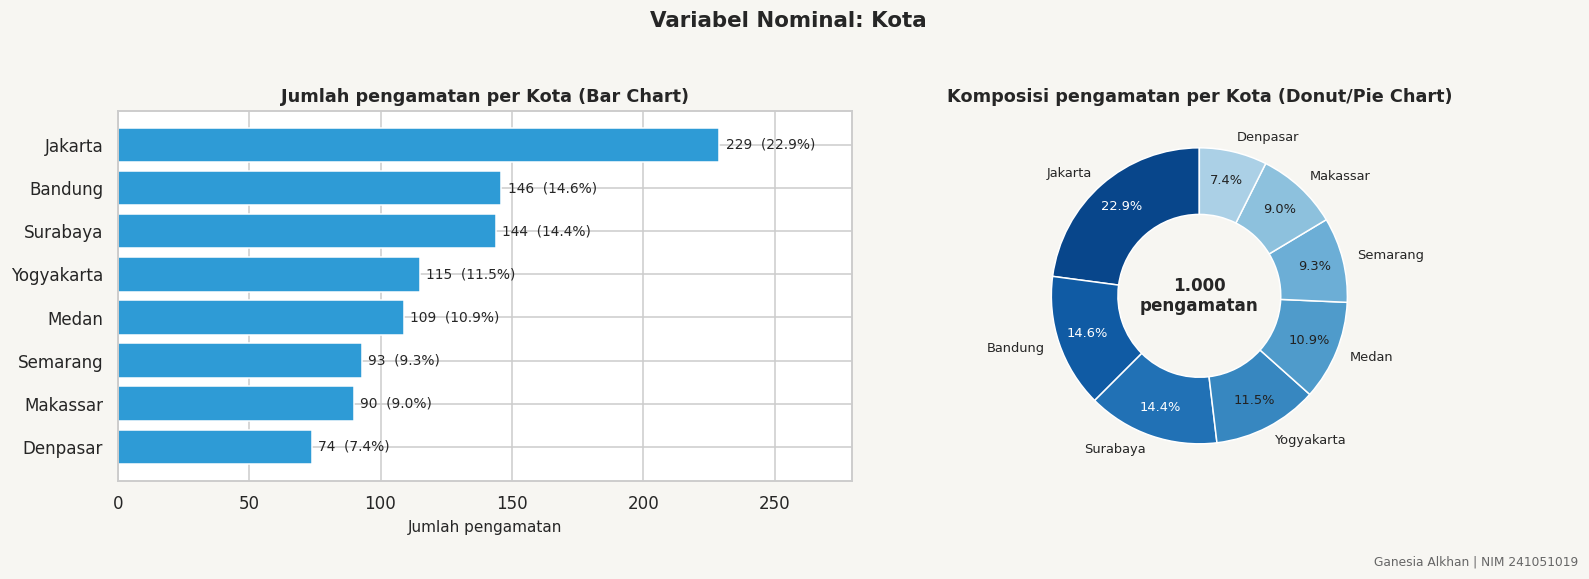

In [5]:
tab_kota = (df.groupby("Kota", observed=True)
              .agg(Jumlah=(SUHU, "size"), Mean_Suhu=(SUHU, "mean"), Median_Suhu=(SUHU, "median"),
                   Mean_RH=(RH, "mean"), Persen_Hujan=("Kondisi", lambda s: s.isin(["Hujan", "Hujan Petir"]).mean() * 100))
              .sort_values("Jumlah", ascending=False))
tab_kota["Persen"] = tab_kota["Jumlah"] / len(df) * 100
print("Modus Kota:", df["Kota"].mode()[0])
display(tab_kota.style.format({"Mean_Suhu": "{:.1f}", "Median_Suhu": "{:.1f}", "Mean_RH": "{:.1f}",
                               "Persen_Hujan": "{:.1f}%", "Persen": "{:.1f}%"}))

fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.2))
urut = tab_kota.sort_values("Jumlah").index.astype(str)
nilai = tab_kota.loc[urut, "Jumlah"]
b = ax[0].barh(urut, nilai, color=BIRU, edgecolor="white")
ax[0].bar_label(b, labels=[f"{v}  ({v/len(df):.1%})" for v in nilai], padding=4, fontsize=9)
ax[0].set_xlim(0, nilai.max() * 1.22)
ax[0].set(title="Jumlah pengamatan per Kota (Bar Chart)", xlabel="Jumlah pengamatan", ylabel="")

w, t, a = ax[1].pie(tab_kota["Jumlah"], labels=tab_kota.index.astype(str), colors=sns.color_palette("Blues_r", 11)[:8],
                    autopct="%1.1f%%", startangle=90, pctdistance=0.8, textprops={"fontsize": 8.5},
                    wedgeprops=dict(width=0.45, edgecolor="white"))
for x, v in zip(a, tab_kota["Persen"]):
    x.set_color("white" if v > 12 else "#222")
ax[1].set_title("Komposisi pengamatan per Kota (Donut/Pie Chart)")
ax[1].text(0, 0, f"{len(df):,}\npengamatan".replace(",", "."), ha="center", va="center", fontsize=11, fontweight="bold")
selesai(fig, "Variabel Nominal: Kota")

## 6. Kondisi - Kategorik Nominal

Kondisi cuaca juga nominal. Urutan kategori pada grafik (Cerah -> Hujan Petir) hanya untuk **tata letak yang mudah dibaca**, bukan skala ordinal. Selain distribusinya, dilihat juga bagaimana Kondisi **berbeda antar Kota** (dua variabel nominal).

Modus Kondisi: Hujan


,Jumlah,Persen
Kondisi,,
Cerah,222,22.2%
Cerah Berawan,236,23.6%
Berawan,244,24.4%
Hujan,251,25.1%
Hujan Petir,47,4.7%


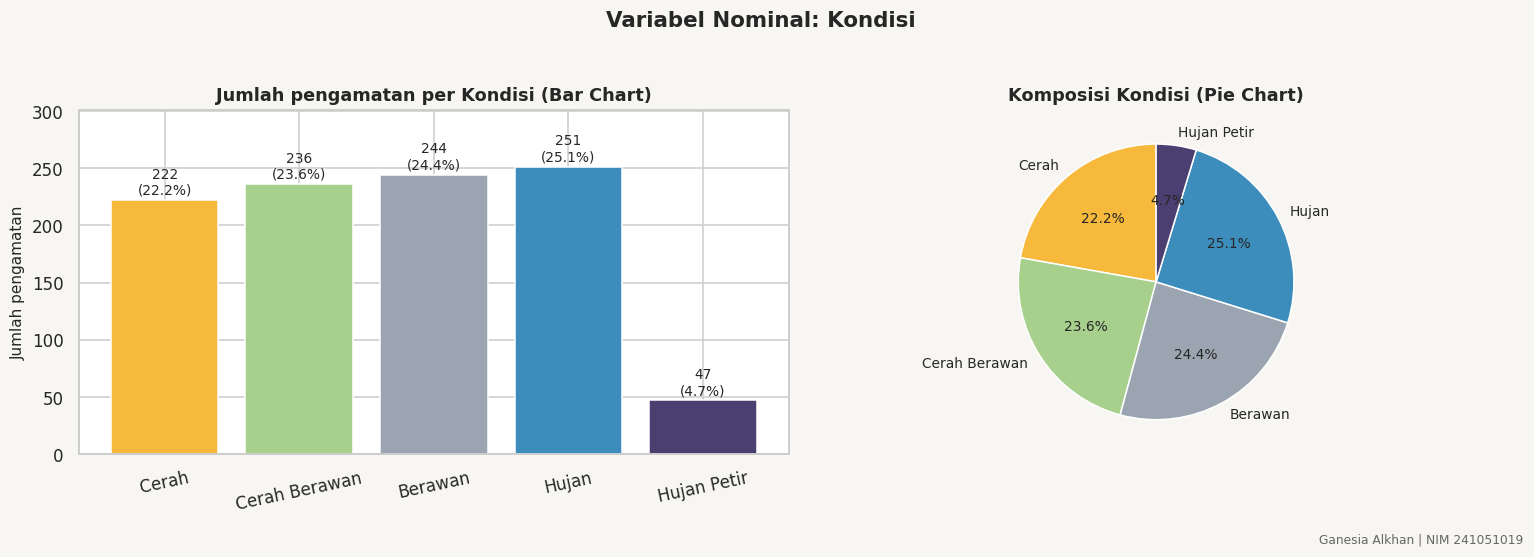

In [6]:
tab_kon = df["Kondisi"].value_counts().reindex(KONDISI).to_frame("Jumlah")
tab_kon["Persen"] = tab_kon["Jumlah"] / len(df) * 100
print("Modus Kondisi:", df["Kondisi"].mode()[0])
display(tab_kon.style.format({"Persen": "{:.1f}%"}))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
b = ax[0].bar(KONDISI, tab_kon["Jumlah"], color=[WARNA_KONDISI[k] for k in KONDISI], edgecolor="white")
ax[0].bar_label(b, labels=[f"{v}\n({p:.1f}%)" for v, p in zip(tab_kon["Jumlah"], tab_kon["Persen"])], fontsize=9, padding=2)
ax[0].set_ylim(0, tab_kon["Jumlah"].max() * 1.2)
ax[0].set(title="Jumlah pengamatan per Kondisi (Bar Chart)", ylabel="Jumlah pengamatan")
ax[0].tick_params(axis="x", labelrotation=12)

ax[1].pie(tab_kon["Jumlah"], labels=KONDISI, colors=[WARNA_KONDISI[k] for k in KONDISI], autopct="%1.1f%%", startangle=90,
          textprops={"fontsize": 9}, wedgeprops=dict(edgecolor="white"))
ax[1].set_title("Komposisi Kondisi (Pie Chart)")
selesai(fig, "Variabel Nominal: Kondisi")

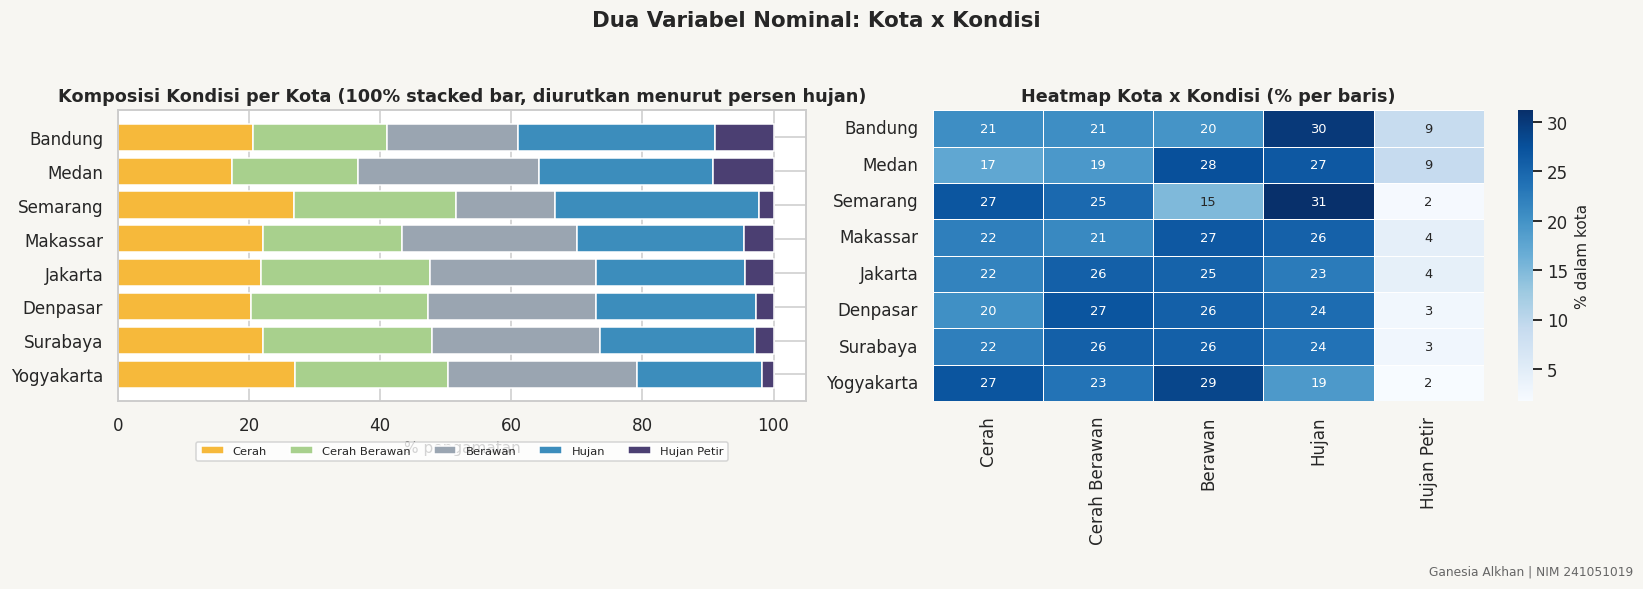

Chi-square Kota x Kondisi: chi2 = 33.3, dof = 28, p = 0.226, Cramer's V = 0.091
Cramer's V: ~0.1 kecil, ~0.3 sedang, >= 0.5 besar.


In [7]:
ct = pd.crosstab(df["Kota"], df["Kondisi"]).reindex(columns=KONDISI)
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
urut_hujan = (ct_pct["Hujan"] + ct_pct["Hujan Petir"]).sort_values().index

fig, ax = plt.subplots(1, 2, figsize=(15, 5.3))
left = np.zeros(len(urut_hujan))
for k in KONDISI:
    v = ct_pct.loc[urut_hujan, k].values
    ax[0].barh(urut_hujan.astype(str), v, left=left, color=WARNA_KONDISI[k], edgecolor="white", label=k)
    left += v
ax[0].set(title="Komposisi Kondisi per Kota (100% stacked bar, diurutkan menurut persen hujan)", xlabel="% pengamatan", ylabel="")
ax[0].legend(ncol=5, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.12))

sns.heatmap(ct_pct.loc[urut_hujan[::-1]], annot=True, fmt=".0f", cmap="Blues", linewidths=.5, cbar_kws={"label": "% dalam kota"}, ax=ax[1], annot_kws={"fontsize": 8.5})
ax[1].set(title="Heatmap Kota x Kondisi (% per baris)", xlabel="", ylabel="")
selesai(fig, "Dua Variabel Nominal: Kota x Kondisi")

chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
v_cramer = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))
print(f"Chi-square Kota x Kondisi: chi2 = {chi2:.1f}, dof = {dof}, p = {p_chi:.3g}, Cramer's V = {v_cramer:.3f}")
print("Cramer's V: ~0.1 kecil, ~0.3 sedang, >= 0.5 besar.")

## 7. Suhu (°C) - Numerik Interval

Pada skala **interval**, selisih antar nilai bermakna (30 °C lebih panas 10 °C dari 20 °C), tetapi **0 °C bukan nol absolut**. Konsekuensinya: mean, median, simpangan baku, dan korelasi **sah**, sedangkan **rasio** dan **koefisien variasi** **tidak sah**. Visualisasi yang tepat: histogram dan box plot.

In [8]:
t = df[SUHU]
desk = t.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("Suhu (°C)")
desk.loc["skewness"] = stats.skew(t)
desk.loc["kurtosis (excess)"] = stats.kurtosis(t)
desk.loc["IQR"] = t.quantile(.75) - t.quantile(.25)
display(desk.style.format("{:.2f}"))
print("Catatan: koefisien variasi (SD/mean) sengaja TIDAK dihitung untuk suhu, karena tidak bermakna pada skala interval (lihat demonstrasi di bawah).")

q1, q3 = t.quantile([.25, .75]); iqr = q3 - q1
out = df[(t < q1 - 1.5 * iqr) | (t > q3 + 1.5 * iqr)]
print(f"Pencilan IQR: {len(out)} pengamatan ({len(out)/len(df):.1%})")
n_s, p_n = stats.normaltest(t)
print(f"Uji kenormalan D'Agostino: p = {p_n:.3g} -> {'tolak' if p_n < .05 else 'tidak menolak'} H0 (normal)")

,Suhu (°C)
count,1000.00
mean,26.63
std,3.64
min,15.10
5%,20.40
25%,24.30
50%,26.80
75%,29.10
95%,32.30
max,35.70


Catatan: koefisien variasi (SD/mean) sengaja TIDAK dihitung untuk suhu, karena tidak bermakna pada skala interval (lihat demonstrasi di bawah).
Pencilan IQR: 15 pengamatan (1.5%)
Uji kenormalan D'Agostino: p = 3.35e-06 -> tolak H0 (normal)


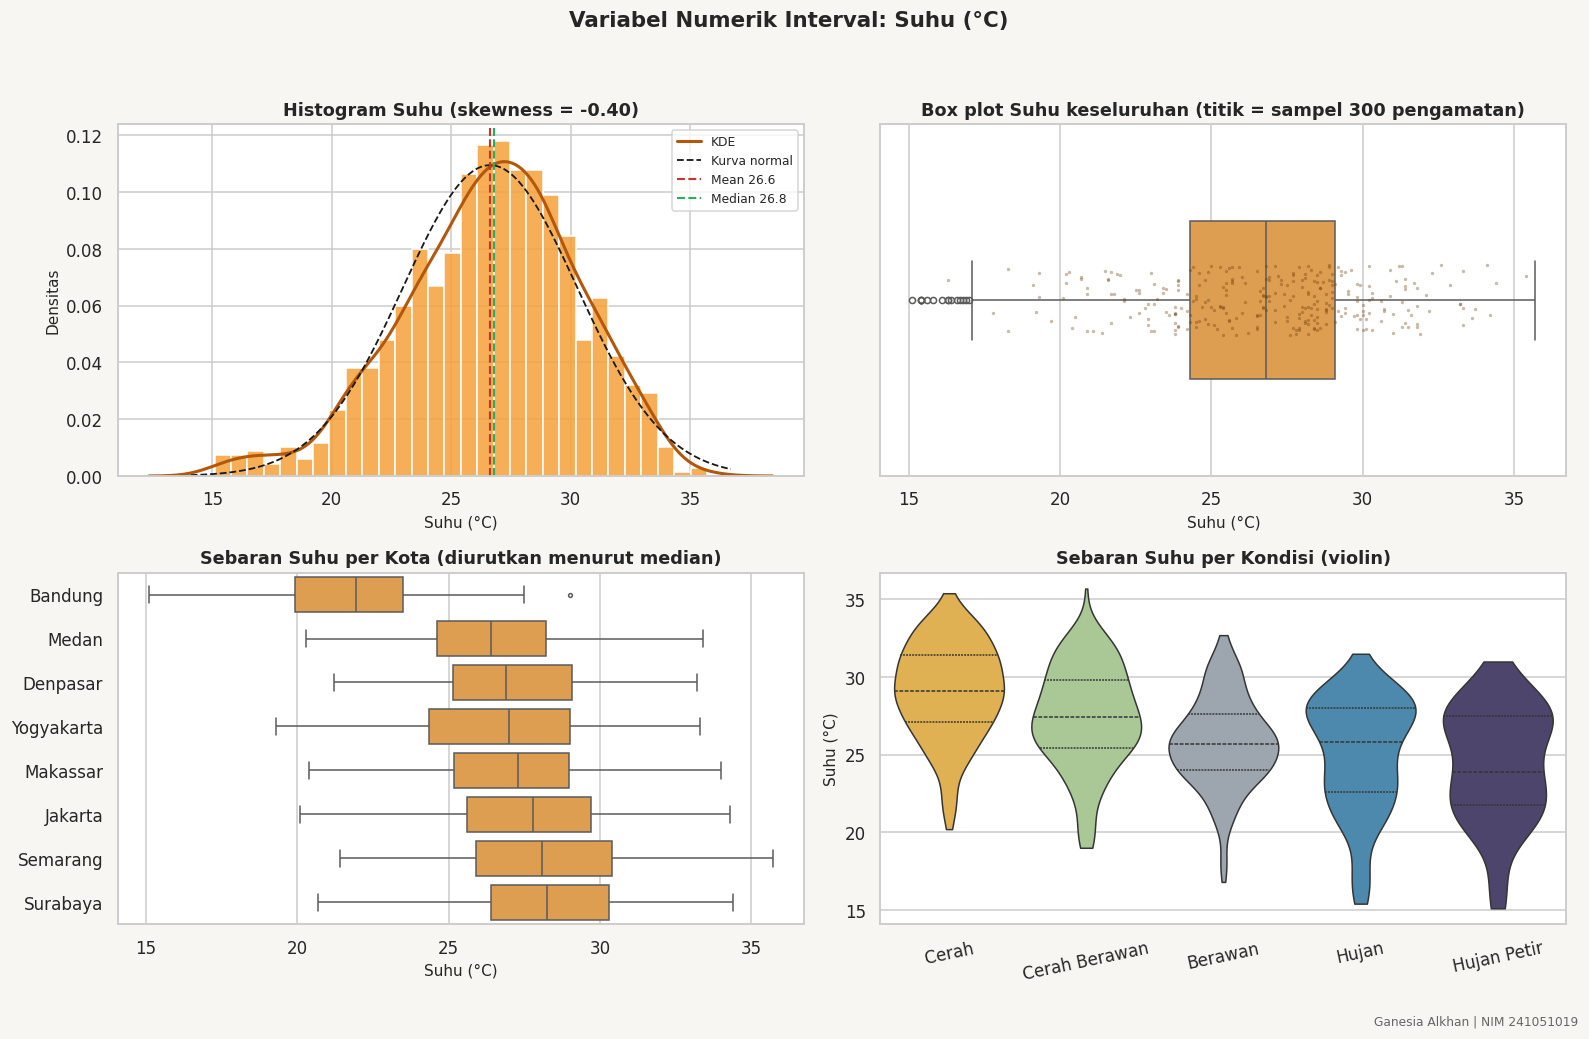

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(14.5, 9.5))

sns.histplot(t, bins=30, stat="density", color=ORANYE, edgecolor="white", alpha=.85, ax=ax[0, 0])
sns.kdeplot(t, color="#B4570A", lw=2, ax=ax[0, 0], label="KDE")
xs = np.linspace(t.min() - 1, t.max() + 1, 300)
ax[0, 0].plot(xs, stats.norm.pdf(xs, t.mean(), t.std()), "k--", lw=1.2, label="Kurva normal")
ax[0, 0].axvline(t.mean(), color="#C0392B", ls="--", lw=1.4, label=f"Mean {t.mean():.1f}")
ax[0, 0].axvline(t.median(), color="#27AE60", ls="--", lw=1.4, label=f"Median {t.median():.1f}")
ax[0, 0].set(title=f"Histogram Suhu (skewness = {stats.skew(t):.2f})", xlabel="Suhu (°C)", ylabel="Densitas")
ax[0, 0].legend(fontsize=8)

sns.boxplot(x=t, color=ORANYE, fliersize=4, width=.45, ax=ax[0, 1])
sns.stripplot(x=t.sample(300, random_state=1), color="#6b3a05", size=2.2, alpha=.35, ax=ax[0, 1])
ax[0, 1].set(title="Box plot Suhu keseluruhan (titik = sampel 300 pengamatan)", xlabel="Suhu (°C)")

urut_k = df.groupby("Kota", observed=True)[SUHU].median().sort_values().index.astype(str)
sns.boxplot(data=df.assign(Kota=df["Kota"].astype(str)), y="Kota", x=SUHU, order=urut_k, color=ORANYE, fliersize=2.5, linewidth=1, ax=ax[1, 0])
ax[1, 0].set(title="Sebaran Suhu per Kota (diurutkan menurut median)", ylabel="", xlabel="Suhu (°C)")

sns.violinplot(data=df.assign(Kondisi=df["Kondisi"].astype(str)), x="Kondisi", y=SUHU, order=KONDISI, hue="Kondisi",
               palette=WARNA_KONDISI, inner="quartile", cut=0, linewidth=1, legend=False, ax=ax[1, 1])
ax[1, 1].set(title="Sebaran Suhu per Kondisi (violin)", xlabel="", ylabel="Suhu (°C)")
ax[1, 1].tick_params(axis="x", labelrotation=12)
selesai(fig, "Variabel Numerik Interval: Suhu (°C)")

### Demonstrasi: mengapa rasio dan koefisien variasi tidak sah untuk suhu (interval)

Jika suhu benar-benar berskala rasio, pernyataan "20 °C dua kali lebih panas dari 10 °C" harus tetap benar **apa pun satuannya**. Mari uji dengan mengonversi ke Kelvin (yang memiliki nol absolut) dan Fahrenheit.

In [10]:
demo = pd.DataFrame({"°C": [10.0, 20.0, 30.0]})
demo["K (nol absolut)"] = demo["°C"] + 273.15
demo["°F"] = demo["°C"] * 9 / 5 + 32

rasio = pd.DataFrame({
    "Rasio 20 / 10": [demo[c].iloc[1] / demo[c].iloc[0] for c in demo.columns],
    "Rasio selisih (30-20)/(20-10)": [(demo[c].iloc[2] - demo[c].iloc[1]) / (demo[c].iloc[1] - demo[c].iloc[0]) for c in demo.columns],
}, index=demo.columns)
display(demo.style.format("{:.2f}"))
display(rasio.style.format("{:.3f}"))
print("-> Rasio 20/10 berubah-ubah menurut satuan (2,00 / 1,04 / 1,36), jadi 'dua kali lebih panas' tidak bermakna.")
print("-> Rasio SELISIH selalu 1,000 di semua satuan, jadi perbandingan jarak (interval) bermakna.")

# Koefisien variasi pada data nyata: berubah bila satuan diganti
kel = pd.DataFrame({"Satuan": ["°C", "K", "°F"],
                    "Mean": [t.mean(), (t + 273.15).mean(), (t * 9 / 5 + 32).mean()],
                    "SD": [t.std(), (t + 273.15).std(), (t * 9 / 5 + 32).std()]})
kel["CV (SD/mean) %"] = kel["SD"] / kel["Mean"] * 100
display(kel.style.format({"Mean": "{:.2f}", "SD": "{:.2f}", "CV (SD/mean) %": "{:.2f}"}).hide(axis="index"))
print("-> CV suhu berubah dari satuan ke satuan (bergantung titik nol yang arbitrer), sehingga CV tidak sah untuk skala interval.")

# Korelasi tidak berubah oleh konversi linear (sah untuk interval)
print(f"Korelasi Suhu-Kelembaban: dalam °C = {t.corr(df[RH]):.4f} | dalam °F = {(t*9/5+32).corr(df[RH]):.4f} (identik)")

,°C,K (nol absolut),°F
0,10.00,283.15,50.00
1,20.00,293.15,68.00
2,30.00,303.15,86.00


,Rasio 20 / 10,Rasio selisih (30-20)/(20-10)
°C,2.000,1.000
K (nol absolut),1.035,1.000
°F,1.360,1.000


-> Rasio 20/10 berubah-ubah menurut satuan (2,00 / 1,04 / 1,36), jadi 'dua kali lebih panas' tidak bermakna.
-> Rasio SELISIH selalu 1,000 di semua satuan, jadi perbandingan jarak (interval) bermakna.


Satuan,Mean,SD,CV (SD/mean) %
°C,26.63,3.64,13.69
K,299.78,3.64,1.22
°F,79.93,6.56,8.21


-> CV suhu berubah dari satuan ke satuan (bergantung titik nol yang arbitrer), sehingga CV tidak sah untuk skala interval.
Korelasi Suhu-Kelembaban: dalam °C = -0.7785 | dalam °F = -0.7785 (identik)


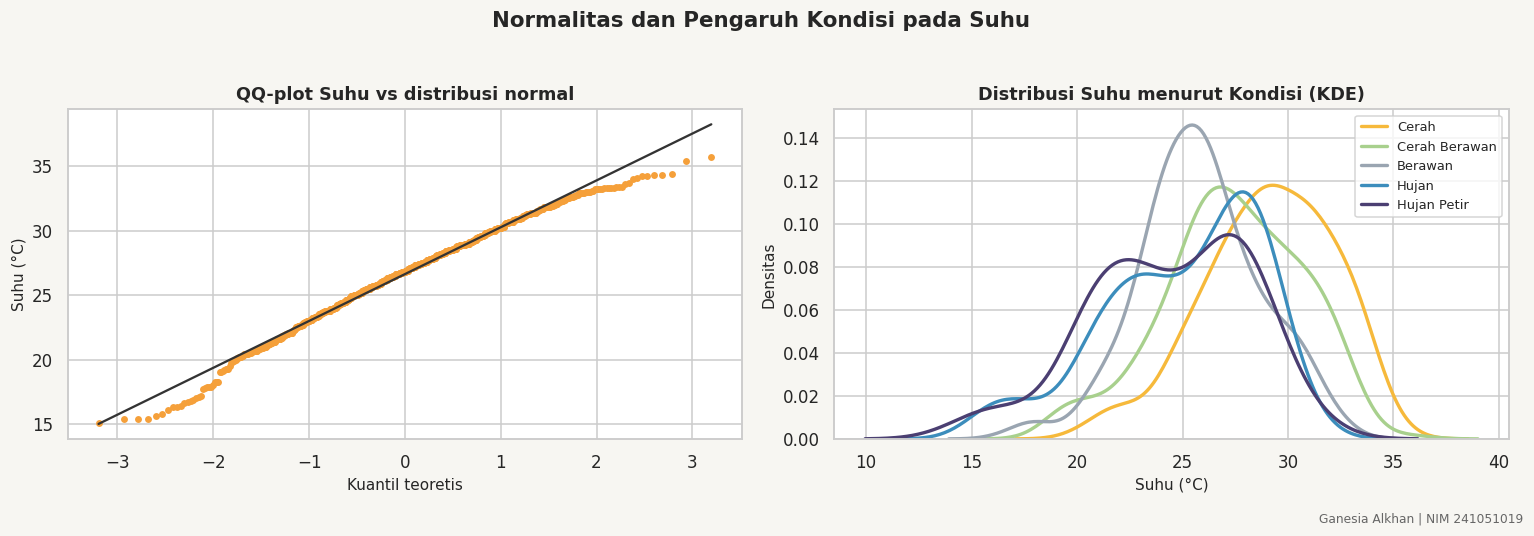

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
stats.probplot(t, dist="norm", plot=ax[0])
ax[0].get_lines()[0].set(color=ORANYE, markersize=3.5); ax[0].get_lines()[1].set(color="#333")
ax[0].set(title="QQ-plot Suhu vs distribusi normal", xlabel="Kuantil teoretis", ylabel="Suhu (°C)")
for k in KONDISI:
    sns.kdeplot(df.loc[df["Kondisi"] == k, SUHU], color=WARNA_KONDISI[k], lw=2.2, label=k, ax=ax[1])
ax[1].set(title="Distribusi Suhu menurut Kondisi (KDE)", xlabel="Suhu (°C)", ylabel="Densitas")
ax[1].legend(fontsize=8.5)
selesai(fig, "Normalitas dan Pengaruh Kondisi pada Suhu")

## 8. Kelembaban (%) - Numerik Rasio

Kelembaban relatif memiliki **nol absolut** (0% = tidak ada uap air), sehingga seluruh operasi rasio **sah**: perbandingan ("80% dua kali 40%") dan koefisien variasi. Karena dibatasi maksimum 100%, distribusinya cenderung **miring ke kiri**. Visualisasi: histogram dan box plot.

In [12]:
h = df[RH]
desk_h = h.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("Kelembaban (%)")
desk_h.loc["skewness"] = stats.skew(h)
desk_h.loc["kurtosis (excess)"] = stats.kurtosis(h)
desk_h.loc["IQR"] = h.quantile(.75) - h.quantile(.25)
desk_h.loc["koef. variasi (%)"] = h.std() / h.mean() * 100        # sah karena skala rasio
desk_h.loc["modus"] = h.mode()[0]
display(desk_h.style.format("{:.2f}"))

q1h, q3h = h.quantile([.25, .75]); iqrh = q3h - q1h
outh = df[(h < q1h - 1.5 * iqrh) | (h > q3h + 1.5 * iqrh)]
print(f"Pencilan IQR: {len(outh)} pengamatan ({len(outh)/len(df):.1%}) | pengamatan dengan RH = 100%: {(h == 100).sum()}")
print(f"Pengamatan lembap (RH >= 80%): {(h >= 80).mean():.1%} | sangat lembap (RH >= 90%): {(h >= 90).mean():.1%}")
n_h, p_h = stats.normaltest(h)
print(f"Uji kenormalan D'Agostino: p = {p_h:.3g} -> {'tolak' if p_h < .05 else 'tidak menolak'} H0 (normal)")
print(f"Karena rasio: RH 80% berarti uap air relatif 2x dari RH 40% (rasio {80/40:.1f}x) - pernyataan ini sah.")

,Kelembaban (%)
count,1000.00
mean,78.37
std,10.51
min,46.00
5%,61.00
25%,71.00
50%,79.00
75%,86.00
95%,96.00
max,100.00


Pencilan IQR: 1 pengamatan (0.1%) | pengamatan dengan RH = 100%: 6
Pengamatan lembap (RH >= 80%): 47.2% | sangat lembap (RH >= 90%): 16.1%
Uji kenormalan D'Agostino: p = 0.00042 -> tolak H0 (normal)
Karena rasio: RH 80% berarti uap air relatif 2x dari RH 40% (rasio 2.0x) - pernyataan ini sah.


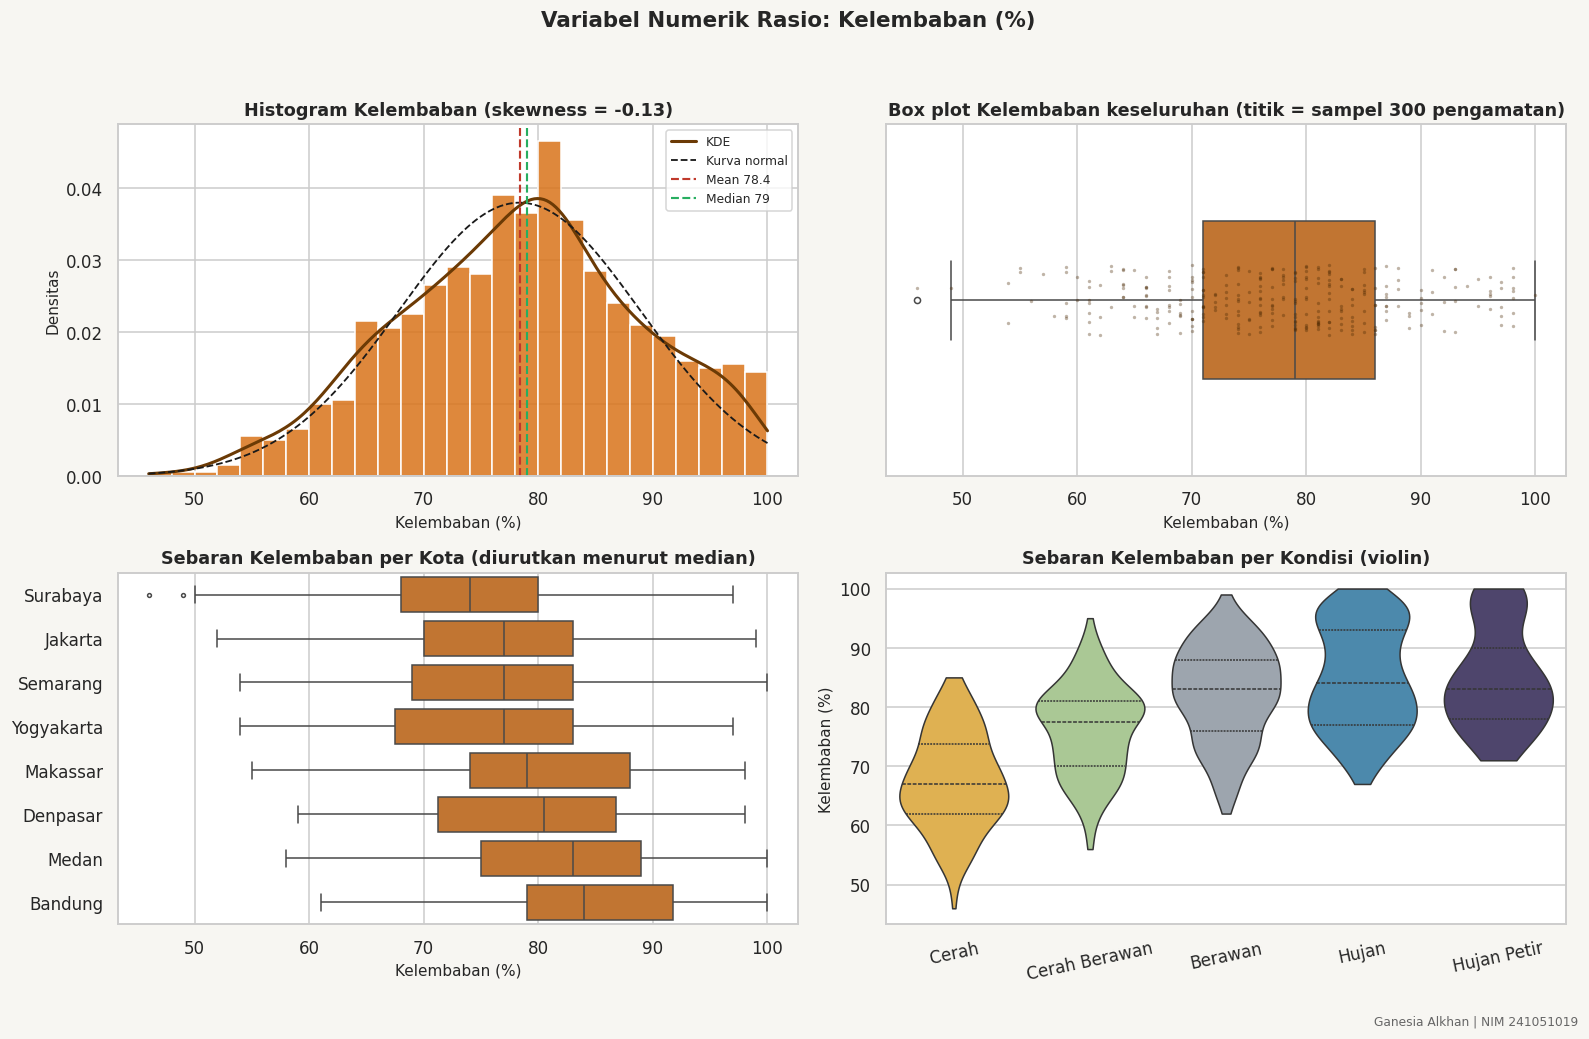

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(14.5, 9.5))

sns.histplot(h, binwidth=2, stat="density", color=ORANYE_TUA, edgecolor="white", alpha=.85, ax=ax[0, 0])
sns.kdeplot(h, color="#6b3a05", lw=2, clip=(h.min(), 100), ax=ax[0, 0], label="KDE")
xs = np.linspace(h.min(), 100, 300)
ax[0, 0].plot(xs, stats.norm.pdf(xs, h.mean(), h.std()), "k--", lw=1.2, label="Kurva normal")
ax[0, 0].axvline(h.mean(), color="#C0392B", ls="--", lw=1.4, label=f"Mean {h.mean():.1f}")
ax[0, 0].axvline(h.median(), color="#27AE60", ls="--", lw=1.4, label=f"Median {h.median():.0f}")
ax[0, 0].set(title=f"Histogram Kelembaban (skewness = {stats.skew(h):.2f})", xlabel="Kelembaban (%)", ylabel="Densitas")
ax[0, 0].legend(fontsize=8)

sns.boxplot(x=h, color=ORANYE_TUA, fliersize=4, width=.45, ax=ax[0, 1])
sns.stripplot(x=h.sample(300, random_state=1), color="#4a2803", size=2.2, alpha=.35, ax=ax[0, 1])
ax[0, 1].set(title="Box plot Kelembaban keseluruhan (titik = sampel 300 pengamatan)", xlabel="Kelembaban (%)")

urut_h = df.groupby("Kota", observed=True)[RH].median().sort_values().index.astype(str)
sns.boxplot(data=df.assign(Kota=df["Kota"].astype(str)), y="Kota", x=RH, order=urut_h, color=ORANYE_TUA, fliersize=2.5, linewidth=1, ax=ax[1, 0])
ax[1, 0].set(title="Sebaran Kelembaban per Kota (diurutkan menurut median)", ylabel="", xlabel="Kelembaban (%)")

sns.violinplot(data=df.assign(Kondisi=df["Kondisi"].astype(str)), x="Kondisi", y=RH, order=KONDISI, hue="Kondisi",
               palette=WARNA_KONDISI, inner="quartile", cut=0, linewidth=1, legend=False, ax=ax[1, 1])
ax[1, 1].set(title="Sebaran Kelembaban per Kondisi (violin)", xlabel="", ylabel="Kelembaban (%)")
ax[1, 1].tick_params(axis="x", labelrotation=12)
selesai(fig, "Variabel Numerik Rasio: Kelembaban (%)")

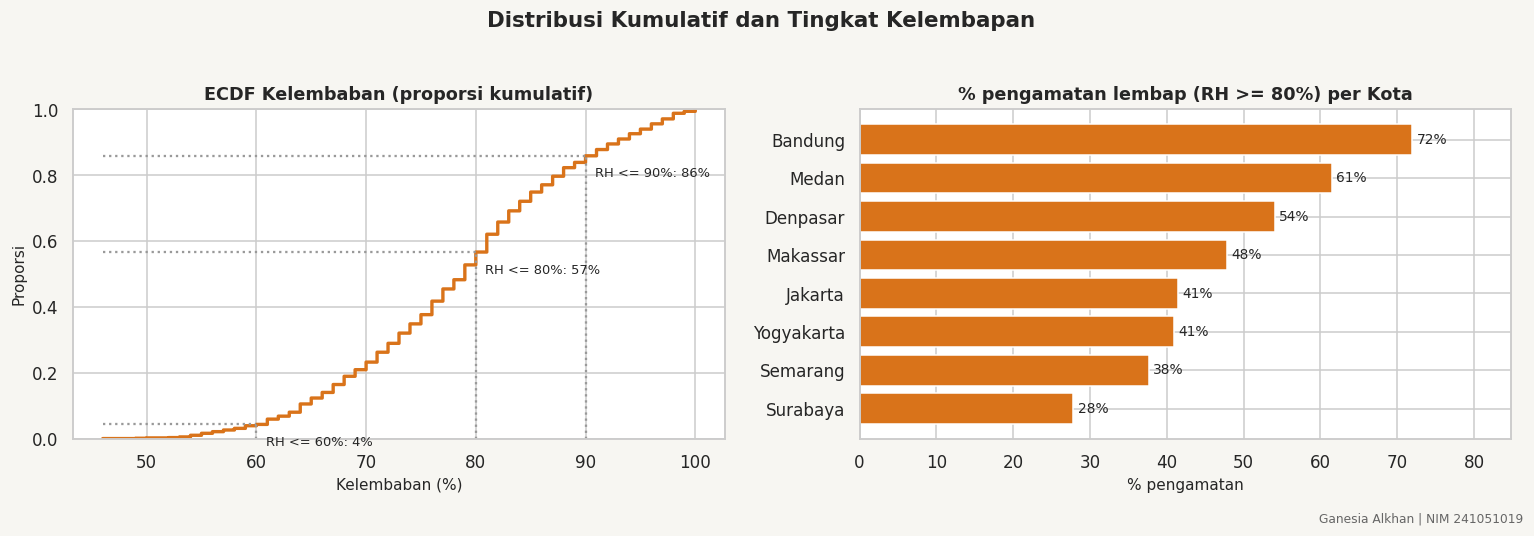

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.ecdfplot(h, color=ORANYE_TUA, lw=2.2, ax=ax[0])
for thr in (60, 80, 90):
    p = (h <= thr).mean()
    ax[0].hlines(p, h.min(), thr, color="#999", ls=":"); ax[0].vlines(thr, 0, p, color="#999", ls=":")
    ax[0].annotate(f"RH <= {thr}%: {p:.0%}", (thr, p), xytext=(6, -14), textcoords="offset points", fontsize=8.5)
ax[0].set(title="ECDF Kelembaban (proporsi kumulatif)", xlabel="Kelembaban (%)", ylabel="Proporsi")

lembap = (df.assign(L=df[RH] >= 80).groupby("Kota", observed=True)["L"].mean() * 100).sort_values()
b = ax[1].barh(lembap.index.astype(str), lembap.values, color=ORANYE_TUA, edgecolor="white")
ax[1].bar_label(b, fmt="%.0f%%", padding=3, fontsize=9)
ax[1].set_xlim(0, lembap.max() * 1.18)
ax[1].set(title="% pengamatan lembap (RH >= 80%) per Kota", xlabel="% pengamatan", ylabel="")
selesai(fig, "Distribusi Kumulatif dan Tingkat Kelembapan")

## 9. Hubungan Antar Variabel

Suhu (interval) dan Kelembaban (rasio) sama-sama numerik, sehingga korelasi **Pearson** (linear) dan **Spearman** (peringkat) dapat dihitung. Perbedaan antar kelompok nominal (Kota dan Kondisi) diuji dengan **Kruskal-Wallis**.

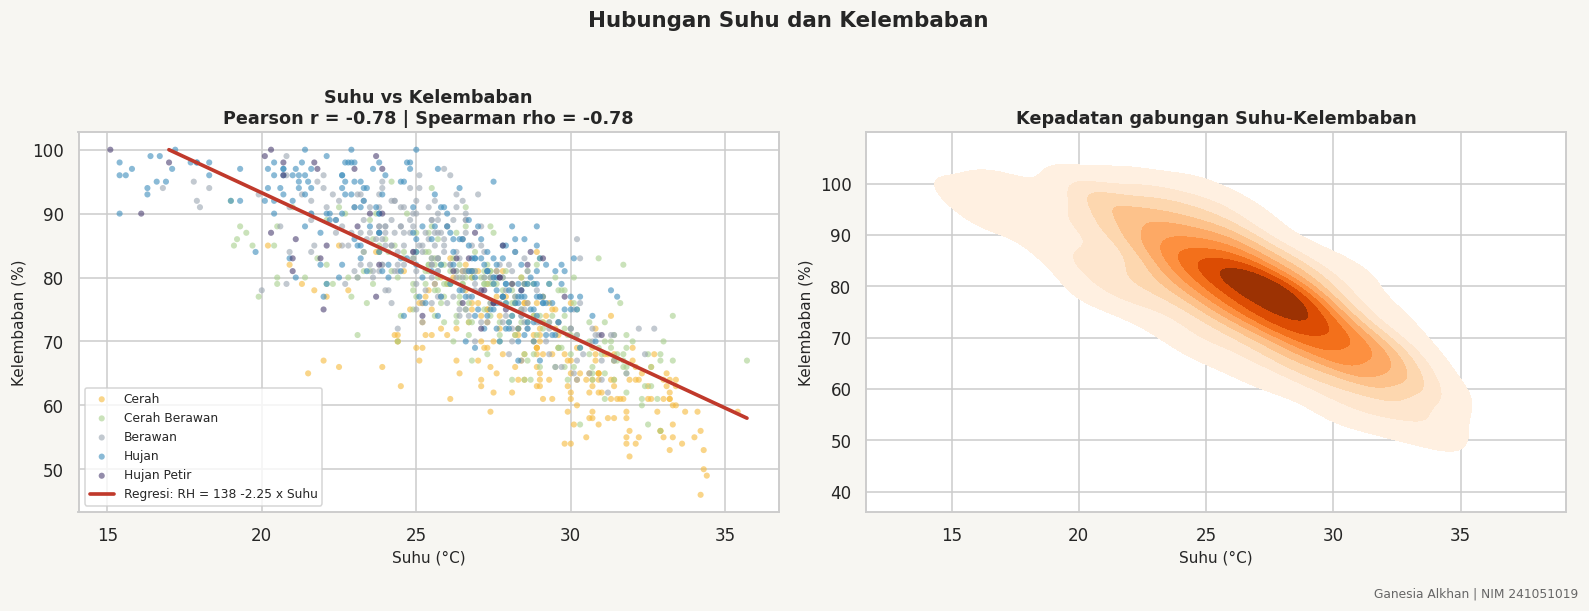

Setiap kenaikan 1 °C diikuti penurunan kelembaban rata-rata 2.25 poin persentase (R^2 = 0.61).


In [15]:
r_p, p_p = stats.pearsonr(df[SUHU], df[RH])
r_s, p_s = stats.spearmanr(df[SUHU], df[RH])
kof = np.polyfit(df[SUHU], df[RH], 1)

fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.5))
for k in KONDISI:
    d = df[df["Kondisi"] == k]
    ax[0].scatter(d[SUHU], d[RH], s=16, alpha=.6, color=WARNA_KONDISI[k], edgecolor="none", label=k)
xs = np.array([max(df[SUHU].min(), (100 - kof[1]) / kof[0]), df[SUHU].max()])   # garis dipotong di RH = 100%
ax[0].plot(xs, kof[0] * xs + kof[1], color="#C0392B", lw=2.4, label=f"Regresi: RH = {kof[1]:.0f} {kof[0]:+.2f} x Suhu")
ax[0].set(title=f"Suhu vs Kelembaban\nPearson r = {r_p:+.2f} | Spearman rho = {r_s:+.2f}", xlabel="Suhu (°C)", ylabel="Kelembaban (%)")
ax[0].legend(fontsize=8)

sns.kdeplot(data=df, x=SUHU, y=RH, fill=True, cmap="Oranges", levels=10, thresh=.03, ax=ax[1])
ax[1].set(title="Kepadatan gabungan Suhu-Kelembaban", xlabel="Suhu (°C)", ylabel="Kelembaban (%)")
selesai(fig, "Hubungan Suhu dan Kelembaban")
print(f"Setiap kenaikan 1 °C diikuti penurunan kelembaban rata-rata {abs(kof[0]):.2f} poin persentase (R^2 = {r_p**2:.2f}).")

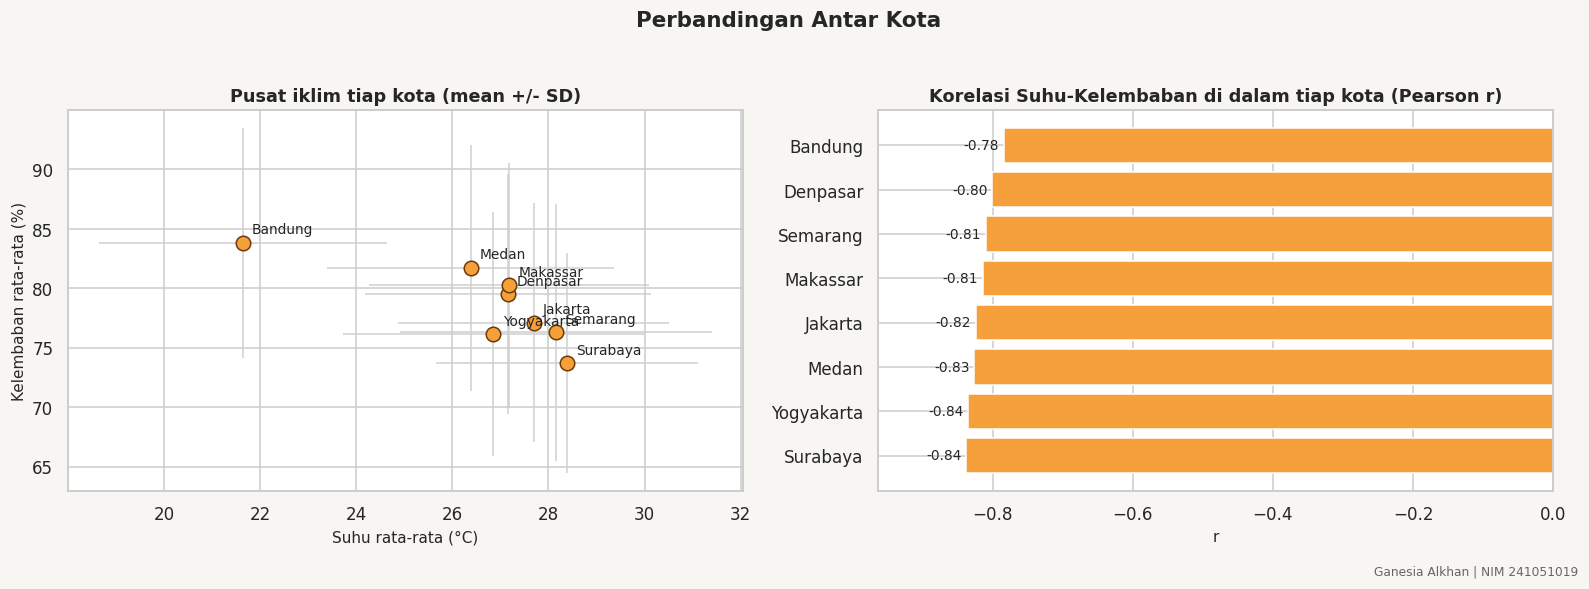

In [16]:
# Pusat iklim per kota dan korelasi di dalam kota
agg = df.groupby("Kota", observed=True).agg(T=(SUHU, "mean"), Ts=(SUHU, "std"), H=(RH, "mean"), Hs=(RH, "std"))
r_kota = pd.Series({k: g[SUHU].corr(g[RH]) for k, g in df.groupby("Kota", observed=True)}).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.3))
ax[0].errorbar(agg["T"], agg["H"], xerr=agg["Ts"], yerr=agg["Hs"], fmt="none", ecolor="#CFCFCF", lw=1, zorder=1)
ax[0].scatter(agg["T"], agg["H"], s=90, color=ORANYE, edgecolor="#6b3a05", zorder=3)
for k, r in agg.iterrows():
    ax[0].annotate(str(k), (r["T"], r["H"]), xytext=(6, 6), textcoords="offset points", fontsize=9)
ax[0].set(title="Pusat iklim tiap kota (mean +/- SD)", xlabel="Suhu rata-rata (°C)", ylabel="Kelembaban rata-rata (%)")

b = ax[1].barh(r_kota.index.astype(str), r_kota.values, color=ORANYE, edgecolor="white")
ax[1].bar_label(b, fmt="%.2f", padding=3, fontsize=9)
ax[1].set_xlim(r_kota.min() * 1.15, 0)
ax[1].set(title="Korelasi Suhu-Kelembaban di dalam tiap kota (Pearson r)", xlabel="r", ylabel="")
selesai(fig, "Perbandingan Antar Kota")

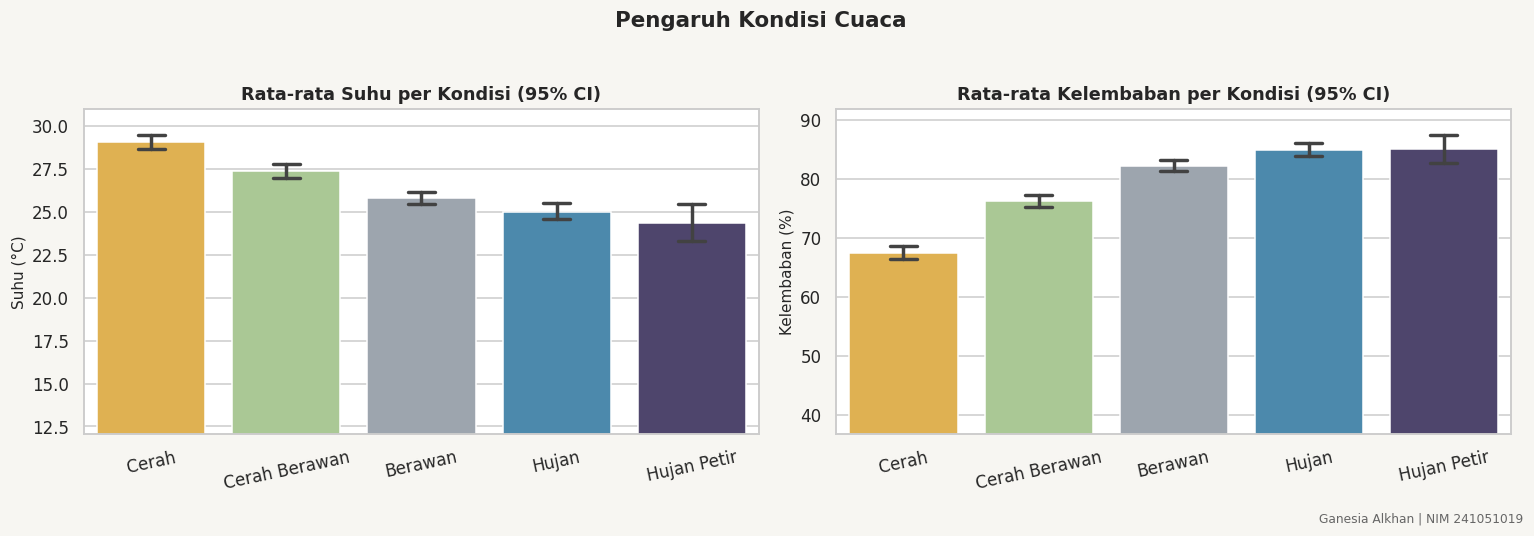

Catatan: sumbu y dipotong agar selisih antar kondisi terlihat jelas; perhatikan nilai sebenarnya pada sumbu.


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
d = df.assign(Kondisi=df["Kondisi"].astype(str))
sns.barplot(data=d, x="Kondisi", y=SUHU, order=KONDISI, hue="Kondisi", palette=WARNA_KONDISI, errorbar=("ci", 95), capsize=.2, legend=False, ax=ax[0])
ax[0].set(title="Rata-rata Suhu per Kondisi (95% CI)", xlabel="", ylabel="Suhu (°C)")
ax[0].set_ylim(d[SUHU].min() * .8, None)
sns.barplot(data=d, x="Kondisi", y=RH, order=KONDISI, hue="Kondisi", palette=WARNA_KONDISI, errorbar=("ci", 95), capsize=.2, legend=False, ax=ax[1])
ax[1].set(title="Rata-rata Kelembaban per Kondisi (95% CI)", xlabel="", ylabel="Kelembaban (%)")
ax[1].set_ylim(d[RH].min() * .8, None)
for a in ax:
    a.tick_params(axis="x", labelrotation=12)
selesai(fig, "Pengaruh Kondisi Cuaca")
print("Catatan: sumbu y dipotong agar selisih antar kondisi terlihat jelas; perhatikan nilai sebenarnya pada sumbu.")

In [18]:
n = len(df)
uji = []
for var in (SUHU, RH):
    for grp in ("Kota", "Kondisi"):
        H, p = stats.kruskal(*[g[var].values for _, g in df.groupby(grp, observed=True)])
        uji.append({"Uji": f"{var} ~ {grp}", "H": H, "p-value": p, "Epsilon^2": H / (n - 1),
                    "Kesimpulan": "berbeda signifikan" if p < .05 else "tidak berbeda signifikan"})
uji = pd.DataFrame(uji)
display(uji.style.format({"H": "{:.1f}", "p-value": "{:.2e}", "Epsilon^2": "{:.3f}"}))
print("Epsilon^2 (ukuran efek): ~0.01 kecil, ~0.06 sedang, >= 0.14 besar.")

hj = df[df["Kondisi"].isin(["Hujan", "Hujan Petir"])]; cr = df[df["Kondisi"] == "Cerah"]
for var in (SUHU, RH):
    u, p = stats.mannwhitneyu(hj[var], cr[var])
    print(f"Hujan (+Petir) vs Cerah, {var}: selisih mean = {hj[var].mean() - cr[var].mean():+.1f}, Mann-Whitney p = {p:.2e}")

,Uji,H,p-value,Epsilon^2,Kesimpulan
0,Suhu (°C) ~ Kota,289.7,9.69e-59,0.290,berbeda signifikan
1,Suhu (°C) ~ Kondisi,184.2,9.19e-39,0.184,berbeda signifikan
2,Kelembaban (%) ~ Kota,93.3,2.56e-17,0.093,berbeda signifikan
3,Kelembaban (%) ~ Kondisi,380.7,4.03e-81,0.381,berbeda signifikan


Epsilon^2 (ukuran efek): ~0.01 kecil, ~0.06 sedang, >= 0.14 besar.
Hujan (+Petir) vs Cerah, Suhu (°C): selisih mean = -4.2, Mann-Whitney p = 2.22e-32
Hujan (+Petir) vs Cerah, Kelembaban (%): selisih mean = +17.5, Mann-Whitney p = 2.87e-62


## 10. Temuan Utama & Kesimpulan

In [19]:
terpanas, tersejuk = agg["T"].idxmax(), agg["T"].idxmin()
terlembap = agg["H"].idxmax()
pct_hujan = df["Kondisi"].isin(["Hujan", "Hujan Petir"]).mean()
hujan_kota = tab_kota["Persen_Hujan"]
mean_k = df.groupby("Kondisi", observed=True)[[SUHU, RH]].mean()

temuan = f"""
**Kota & Kondisi (nominal)**
- Kota dengan pengamatan terbanyak: **{tab_kota.index[0]}** ({tab_kota['Persen'].iloc[0]:.1f}%). Kondisi paling sering: **{df['Kondisi'].mode()[0]}** ({tab_kon['Persen'].max():.1f}%); hujan (termasuk petir) terjadi pada {pct_hujan:.1%} pengamatan.
- Persentase hujan tertinggi: **{hujan_kota.idxmax()}** ({hujan_kota.max():.1f}%), terendah: **{hujan_kota.idxmin()}** ({hujan_kota.min():.1f}%). Hubungan Kota x Kondisi: Cramer's V = {v_cramer:.2f} ({'signifikan' if p_chi < .05 else 'tidak signifikan'}).

**Suhu (interval)**
- Rata-rata {t.mean():.1f} °C, median {t.median():.1f} °C, SD {t.std():.1f} °C, rentang {t.min():.1f}-{t.max():.1f} °C. Kota terpanas: **{terpanas}** ({agg.loc[terpanas, 'T']:.1f} °C); tersejuk: **{tersejuk}** ({agg.loc[tersejuk, 'T']:.1f} °C).
- Karena skala interval, suhu **tidak** dibandingkan dengan rasio dan CV tidak dihitung; demonstrasi konversi satuan membuktikan alasannya.

**Kelembaban (rasio)**
- Rata-rata {h.mean():.1f}%, median {h.median():.0f}%, koefisien variasi {h.std()/h.mean()*100:.1f}% (sah karena rasio). {(h >= 80).mean():.0%} pengamatan lembap (RH >= 80%). Kota paling lembap: **{terlembap}** ({agg.loc[terlembap, 'H']:.1f}%).

**Hubungan**
- Suhu dan kelembaban berkorelasi negatif kuat (Pearson r = {r_p:+.2f}; tiap +1 °C kelembaban turun {abs(kof[0]):.2f} poin).
- Kondisi Hujan menurunkan suhu rata-rata menjadi {mean_k.loc['Hujan', SUHU]:.1f} °C dibanding {mean_k.loc['Cerah', SUHU]:.1f} °C saat Cerah, sementara kelembaban naik dari {mean_k.loc['Cerah', RH]:.0f}% menjadi {mean_k.loc['Hujan', RH]:.0f}%.
"""
display(Markdown(temuan))


**Kota & Kondisi (nominal)**
- Kota dengan pengamatan terbanyak: **Jakarta** (22.9%). Kondisi paling sering: **Hujan** (25.1%); hujan (termasuk petir) terjadi pada 29.8% pengamatan.
- Persentase hujan tertinggi: **Bandung** (39.0%), terendah: **Yogyakarta** (20.9%). Hubungan Kota x Kondisi: Cramer's V = 0.09 (tidak signifikan).

**Suhu (interval)**
- Rata-rata 26.6 °C, median 26.8 °C, SD 3.6 °C, rentang 15.1-35.7 °C. Kota terpanas: **Surabaya** (28.4 °C); tersejuk: **Bandung** (21.6 °C).
- Karena skala interval, suhu **tidak** dibandingkan dengan rasio dan CV tidak dihitung; demonstrasi konversi satuan membuktikan alasannya.

**Kelembaban (rasio)**
- Rata-rata 78.4%, median 79%, koefisien variasi 13.4% (sah karena rasio). 47% pengamatan lembap (RH >= 80%). Kota paling lembap: **Bandung** (83.8%).

**Hubungan**
- Suhu dan kelembaban berkorelasi negatif kuat (Pearson r = -0.78; tiap +1 °C kelembaban turun 2.25 poin).
- Kondisi Hujan menurunkan suhu rata-rata menjadi 25.0 °C dibanding 29.1 °C saat Cerah, sementara kelembaban naik dari 67% menjadi 85%.


**Kesimpulan.** Data sintetis 1.000 baris berhasil meniru struktur dan tipe data pada gambar tugas, dan analisis menegaskan bahwa **skala pengukuran menentukan analisis yang sah**:
- **Nominal (Kota, Kondisi):** frekuensi, modus, bar chart, dan pie chart.
- **Interval (Suhu):** mean, median, SD, dan korelasi sah; **rasio dan koefisien variasi tidak sah** (terbukti lewat konversi °C-K-°F).
- **Rasio (Kelembaban):** seluruh operasi sah, termasuk perbandingan rasio dan koefisien variasi.

## 11. Menjalankan Dashboard Streamlit

File yang disertakan: `app_kasus3.py` dan `data_pengamatan_cuaca.csv` (satu folder). `requirements.txt` yang sama dengan Kasus 1 dapat dipakai.

```bash
pip install -r requirements.txt
streamlit run app_kasus3.py
```

Dashboard memuat identitas **Ganesia Alkhan - NIM 241051019** pada header, sidebar, dan footer.

---
<div style="text-align:right; color:#666">Ganesia Alkhan &nbsp;|&nbsp; NIM 241051019</div>